# RT-DETR

Para el environments usar el fichero requirements.txt de https://github.com/lyuwenyu/RT-DETR/tree/main/rtdetrv2_pytorch. No requiere de ninguna librería propioa

In [ ]:
import sys
!{sys.executable} -m pip install -r RT-DETR/rtdetrv2_pytorch/requirements.txt
!{sys.executable} -m pip install tensorboard faster_coco_eval
!{sys.executable} -m pip install PyYAML
!{sys.executable} -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cu118

In [ ]:
%pip install -r RT-DETR/rtdetrv2_pytorch/requirements.txt

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not open requirements file: [Errno 2] No such file or directory: 'RT-DETR/rtdetrv2_pytorch/requirements.txt'


In [5]:
%pip install tensorboard faster_coco_eval

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os, sys, subprocess, urllib.request
import cv2
import numpy as np
import torch
from PIL import Image
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

REPO = "RT-DETR/rtdetrv2_pytorch"

if not os.path.exists("RT-DETR"):
    subprocess.run(["git", "clone", "--depth", "1", "https://github.com/lyuwenyu/RT-DETR.git"], check=True)
sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))

# Ahora podemos cargar los módulos necesarios.


from src.data.dataset import mscoco_category2name, mscoco_label2category

# Los nombres de las clases vienen del dataset COCO, usado en el entrenamiento del modelo.
CLASS_NAMES = {lab: mscoco_category2name[cat] for lab, cat in list(mscoco_label2category.items())[:9]}  # 0..79
CLASS_NAMES[9] = 'matricula'
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


print (CLASS_NAMES)

{0: 'person', 1: 'bicycle', 2: 'car', 3: 'motorcycle', 4: 'airplane', 5: 'bus', 6: 'train', 7: 'truck', 8: 'boat', 9: 'matricula'}


In [2]:
import sys
import os
import torchvision.transforms as T

sys.path.insert(0, os.path.abspath("RT-DETR/rtdetrv2_pytorch"))

from load_rtdetr import load_rtdetr, load_rtdetr_matriculas
# Se puede elegir cualquier familia v1 o v2 y tamaño: s, m, l y x.
model, postprocessor = load_rtdetr(family="v2", size="l", device=DEVICE)

#Modelo de matrículas
cfg_mat = "RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r50vd_6x_matriculas.yml"
weights_mat = "RT-DETR/rtdetrv2_pytorch/output/rtdetrv2_r50vd_6x_coco/best.pth"
model_mat, post_mat = load_rtdetr_matriculas(cfg_path=cfg_mat, weights_path=weights_mat, device=DEVICE)

@torch.no_grad()
def detect(bgr, conf=0.6, conf_mat=0.6):
    
    #Codigo Coco
    h, w = bgr.shape[:2]
    im = Image.fromarray(cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)).resize((640, 640), Image.BILINEAR)
    x = torch.from_numpy(np.array(im)).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    labels, boxes, scores = postprocessor(model(x), torch.tensor([[w, h]], device=DEVICE))
    labels, boxes, scores = labels[0].cpu().numpy(), boxes[0].cpu().numpy(), scores[0].cpu().numpy()
    keep = scores >= conf  
    
    #Codigo Matriculas
    normalize = T.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    x_mat = normalize(x.squeeze(0)).unsqueeze(0)
    tensor_shape = torch.tensor([[w, h]], device=DEVICE)
    
    labels_m, boxes_m, scores_m = post_mat(model_mat(x_mat), tensor_shape)
    labels_m, boxes_m, scores_m = labels_m[0].cpu().numpy(), boxes_m[0].cpu().numpy(), scores_m[0].cpu().numpy()
    keep_m = scores_m >= conf_mat
    

    labels_m_offset = labels_m[keep_m] * 0 + 9
    
    boxes_final = np.concatenate((boxes[keep], boxes_m[keep_m])) if (keep.any() or keep_m.any()) else np.array([])
    scores_final = np.concatenate((scores[keep], scores_m[keep_m])) if (keep.any() or keep_m.any()) else np.array([])
    labels_final = np.concatenate((labels[keep], labels_m_offset)) if (keep.any() or keep_m.any()) else np.array([])
    
    return boxes_final, scores_final, labels_final

Cargando RT-DETR familia 'v2', tamaño 'l' en cpu
Load PResNet50 state_dict
Cargando RT-DETR personalizado en cpu
 - Config: RT-DETR/rtdetrv2_pytorch/configs/rtdetrv2/rtdetrv2_r50vd_6x_matriculas.yml
 - Pesos: RT-DETR/rtdetrv2_pytorch/output/rtdetrv2_r50vd_6x_coco/best.pth
Load PResNet50 state_dict


(np.float64(-0.5), np.float64(1074.5), np.float64(581.5), np.float64(-0.5))

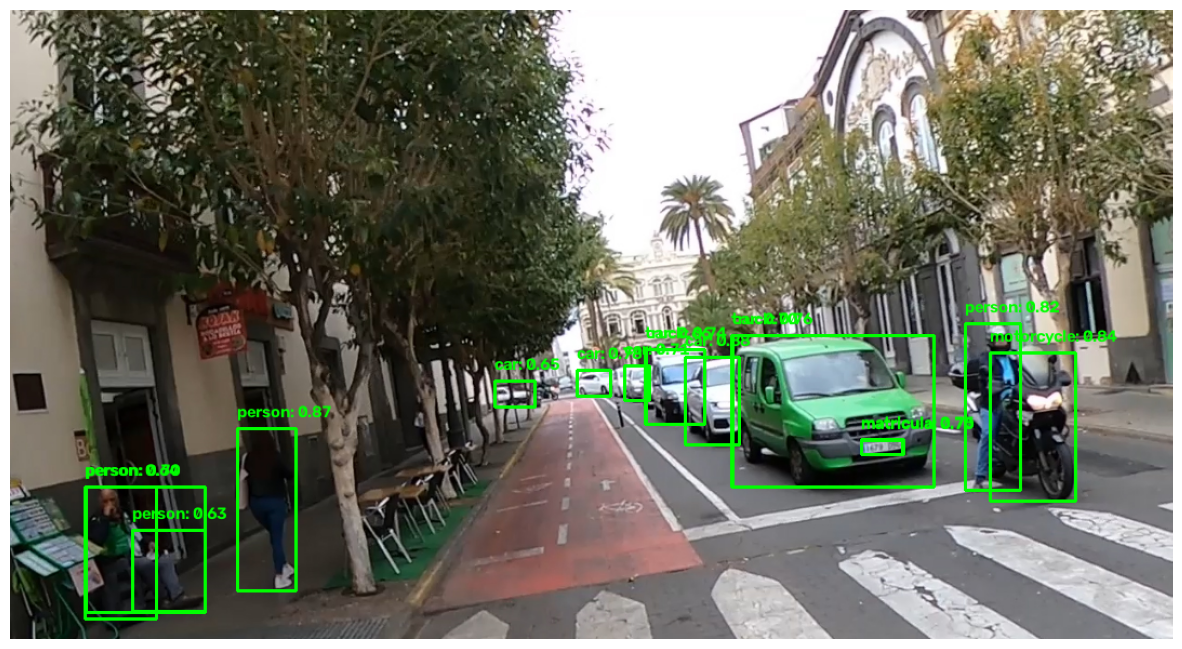

In [3]:
# Ejemplo de uso con imagen estática.

path_test = 'test.jpg'

image = cv2.imread(path_test)

boxes, scores, labels = detect(image, conf=0.6)

for box, score, label in zip(boxes, scores, labels):
    
    if label not in CLASS_NAMES:
        continue
    
    x1, y1, x2, y2 = box.astype(int)
    cv2.rectangle(image, (x1, y1), (x2, y2), (0, 255, 0), 2)
    cv2.putText(image, f"{CLASS_NAMES[label]}: {score:.2f}", (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    
plt.figure(figsize=(15, 10))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.axis('off')



Tarea de detectar Matriculas y distintos objetos en el video

In [27]:
import cv2
import csv
import numpy as np
import math


class detectorObjetos:
    def __init__(self, max_distance=160, max_lost=5):
        self.center_points = {}
        self.id_count = 1
        self.max_distance = max_distance
        self.max_lost = max_lost

    def update(self, objects_rect):
        objects_bbs_ids = []
        
        for obj_id in self.center_points:
            self.center_points[obj_id][3] += 1

        for rect in objects_rect:
            x1, y1, x2, y2, cls, score = rect
            cx = (x1 + x2) // 2
            cy = (y1 + y2) // 2
            
            same_object_detected = False
            min_dist = self.max_distance
            best_id = None
            
            for obj_id, pt in self.center_points.items():
                prev_cx, prev_cy, prev_cls, _ = pt
                dist = math.hypot(cx - prev_cx, cy - prev_cy)
                
                if dist < min_dist and cls == prev_cls:
                    min_dist = dist
                    best_id = obj_id
                    
            if best_id is not None:
                self.center_points[best_id] = [cx, cy, cls, 0]
                objects_bbs_ids.append([x1, y1, x2, y2, best_id, cls, score])
                same_object_detected = True
                    
            if not same_object_detected:
                self.center_points[self.id_count] = [cx, cy, cls, 0]
                objects_bbs_ids.append([x1, y1, x2, y2, self.id_count, cls, score])
                self.id_count += 1
                
        new_center_points = {}
        for obj_id, pt in self.center_points.items():
            if pt[3] <= self.max_lost:
                new_center_points[obj_id] = pt
        self.center_points = new_center_points.copy()
        
        return objects_bbs_ids
    
    
def detectar_matricula_contornos(roi_coche):
    gris = cv2.cvtColor(roi_coche, cv2.COLOR_BGR2GRAY)
    gris = cv2.GaussianBlur(gris, (5, 5), 0)
    bordes = cv2.Canny(gris, 30, 200)
    
    contornos, _ = cv2.findContours(bordes, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    contornos = sorted(contornos, key=cv2.contourArea, reverse=True)[:10]
    
    for c in contornos:
        perimetro = cv2.arcLength(c, True)
        aproximacion = cv2.approxPolyDP(c, 0.018 * perimetro, True)
        
        if len(aproximacion) == 4:
            x, y, w, h = cv2.boundingRect(aproximacion)
            aspect_ratio = w / float(h)
            
            if 2.5 <= aspect_ratio <= 5.5:
                return aproximacion 
                
    return None


vid = cv2.VideoCapture("VideoEjemplo.MP4")
ruta_video_salida = "resultado_final.mp4"

width = 1280
height = 720
fps = int(vid.get(cv2.CAP_PROP_FPS))

out = cv2.VideoWriter(ruta_video_salida, cv2.VideoWriter_fourcc(*'mp4v'), fps, (width, height))

f_csv = open('resultados_tracking.csv', 'w', newline='')
csv_writer = csv.writer(f_csv)
csv_writer.writerow(['fotograma', 'identificador', 'tipo de objeto', 'confianza', 'x1', 'y1', 'x2', 'y2'])

contadores = {} 
ids_vistos = set() 
frame_count = 0
tracker = detectorObjetos(max_distance=80) 

clases_permitidas = ['person', 'car', 'motorcycle', 'bicycle', 'bus', 'truck', 'matricula']

posicion_inicial = {} 
flujo = {"Fondo": 0, "Frente": 0}
ids_contados_flujo = set() 

while True:
    ret, img = vid.read()
    
    if ret: 
        img = cv2.resize(img, (width, height))
        
        frame_count += 1
        
        if frame_count % 2 == 0:
            continue
            
        boxes, scores, labels = detect(img, conf=0.4)

        detections = []
        for (x1, y1, x2, y2), score, cls in zip(boxes, scores, labels):
            nombre_clase = CLASS_NAMES.get(int(cls), "")
            
            if nombre_clase in clases_permitidas:
                detections.append([int(x1), int(y1), int(x2), int(y2), int(cls), score])

        tracked_objects = tracker.update(detections)

        for track in tracked_objects:
            x1, y1, x2, y2, track_id, cls, score = track
            nombre_clase = CLASS_NAMES[cls]
            
            csv_writer.writerow([frame_count, track_id, nombre_clase, f"{score:.2f}", x1, y1, x2, y2])
            
            if track_id not in ids_vistos:
                ids_vistos.add(track_id)
                contadores[nombre_clase] = contadores.get(nombre_clase, 0) + 1
                
            if nombre_clase in clases_permitidas:
                y1_safe, y2_safe = max(0, y1), min(height, y2)
                x1_safe, x2_safe = max(0, x1), min(width, x2)
                
                roi = img[y1_safe:y2_safe, x1_safe:x2_safe]
                
                if roi.size != 0:
                    w_roi = x2_safe - x1_safe
                    h_roi = y2_safe - y1_safe
                    roi_small = cv2.resize(roi, (max(1, w_roi//12), max(1, h_roi//12)), interpolation=cv2.INTER_LINEAR)
                    roi_blurred = cv2.resize(roi_small, (w_roi, h_roi), interpolation=cv2.INTER_NEAREST)
                    
                    img[y1_safe:y2_safe, x1_safe:x2_safe] = roi_blurred

            cy = (y1 + y2) // 2 #Centro vertical

            if track_id not in posicion_inicial:
                posicion_inicial[track_id] = cy

            desplazamiento_y = cy - posicion_inicial[track_id]
            
            direccion = "Fijo"
            if desplazamiento_y > 30: 
                direccion = "Frente" 
            elif desplazamiento_y < -30:
                direccion = "Fondo"  

            linea_fondo = 350 
            linea_frente = 400

            if track_id not in ids_contados_flujo:
                if direccion == "Frente" and cy > linea_frente:
                    flujo["Frente"] += 1
                    ids_contados_flujo.add(track_id)
                elif direccion == "Fondo" and cy < linea_fondo:
                    flujo["Fondo"] += 1
                    ids_contados_flujo.add(track_id)

            color = tuple(int(c) for c in np.random.RandomState(cls).randint(50, 255, 3)) 
            cv2.rectangle(img, (x1, y1), (x2, y2), color, 3)
            cv2.putText(img, f"ID:{track_id} {nombre_clase} {score:.2f}", (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)
            
            if nombre_clase == 'car':
                roi_coche = img[max(0, y1):min(height, y2), max(0, x1):min(width, x2)]
                
                if roi_coche.size != 0:
                    contorno_mat = detectar_matricula_contornos(roi_coche)
                    
                    if contorno_mat is not None:
                        contorno_original = contorno_mat + np.array([x1, y1])
                        cv2.drawContours(img, [contorno_original], -1, (0, 0, 255), 3)
                        px, py = contorno_original[0][0]
                        cv2.putText(img, "Mat. Contorno", (px, py - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 255), 2)

        y_offset = 30
        for clase in clases_permitidas:
            total = contadores.get(clase, 0)
            cv2.putText(img, f"Total {clase}: {total}", (20, y_offset), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2)
            y_offset += 35

        cv2.putText(img, f"Acercandose: {flujo['Frente']}", (1000, 50), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2)
        cv2.putText(img, f"Alejandose: {flujo['Fondo']}", (1000, 50 + 35), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2)

        cv2.imshow("Vid", img)
        out.write(img)

        if cv2.waitKey(1) == 27:
            break
    else:
        break

vid.release()
out.release()
f_csv.close()
cv2.destroyAllWindows()

print(f"¡Proceso terminado! Resultados guardados en CSV y vídeo.")

¡Proceso terminado! Resultados guardados en CSV y vídeo.


Entrenamiento 

In [ ]:
%cd RT-DETR/rtdetrv2_pytorch

!python tools/train.py -c configs/rtdetrv2/rtdetrv2_r50vd_6x_matriculas.yml -t output/rtdetrv2_r50vd_6x_coco/last.pth --use-amp

In [ ]:
!pip install tensorboard

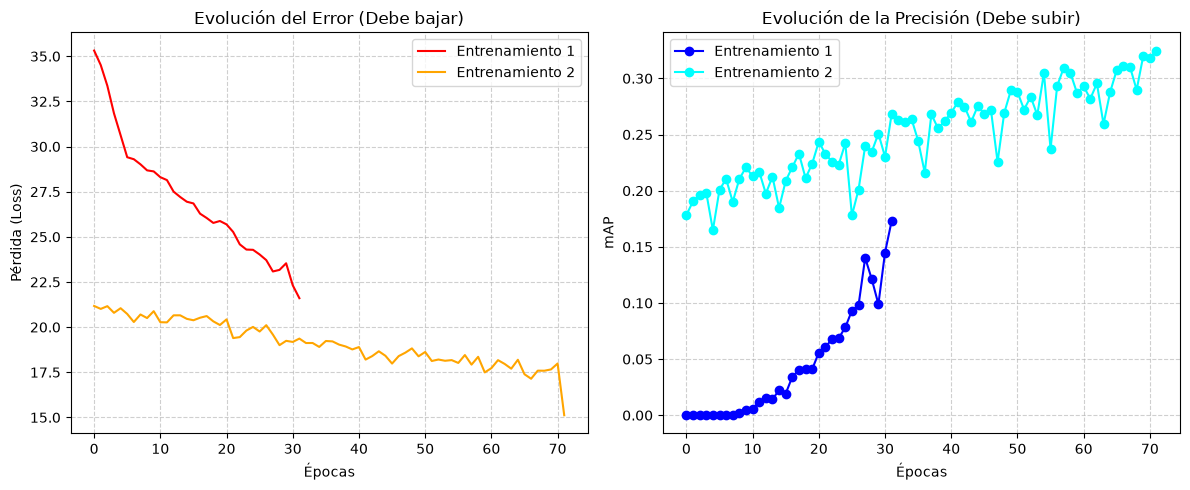

In [ ]:
import matplotlib.pyplot as plt
import json

ruta_log = "RT-DETR/rtdetrv2_pytorch/output/rtdetrv2_r50vd_6x_coco/log.txt"

entrenamientos = [{'epocas_loss': [], 'loss': [], 'epocas_map': [], 'map': []}]
indice_entrenamiento = 0
ultima_epoca = -1

with open(ruta_log, "r", encoding="utf-8") as f:
    for linea in f:
        linea = linea.strip()
        if not linea: 
            continue
            
        try:
            datos = json.loads(linea)
            epoca = datos.get("epoch", 0)

            if epoca < ultima_epoca:
                entrenamientos.append({'epocas_loss': [], 'loss': [], 'epocas_map': [], 'map': []})
                indice_entrenamiento += 1
            
            ultima_epoca = epoca
            
            # Extraer Pérdida
            if "train_loss" in datos:
                entrenamientos[indice_entrenamiento]['loss'].append(datos["train_loss"])
                entrenamientos[indice_entrenamiento]['epocas_loss'].append(epoca)
                
            # Extraer Precisión 
            if "test_coco_eval_bbox" in datos:
                entrenamientos[indice_entrenamiento]['map'].append(datos["test_coco_eval_bbox"][0])
                entrenamientos[indice_entrenamiento]['epocas_map'].append(epoca)
                
        except json.JSONDecodeError:
            pass

plt.figure(figsize=(12, 5))
colores_loss = ["red", "orange", "darkred"]
colores_map = ["blue", "cyan", "darkblue"]

plt.subplot(1, 2, 1)
for i, run in enumerate(entrenamientos):
    if run['loss']:
        color = colores_loss[i % len(colores_loss)]
        plt.plot(run['epocas_loss'], run['loss'], color=color, label=f"Entrenamiento {i+1}")

plt.title("Evolución del Error (Debe bajar)")
plt.xlabel("Épocas")
plt.ylabel("Pérdida (Loss)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.subplot(1, 2, 2)
for i, run in enumerate(entrenamientos):
    if run['map']:
        color = colores_map[i % len(colores_map)]
        plt.plot(run['epocas_map'], run['map'], color=color, marker="o", label=f"Entrenamiento {i+1}")

plt.title("Evolución de la Precisión (Debe subir)")
plt.xlabel("Épocas")
plt.ylabel("mAP")
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend()

plt.tight_layout()
plt.show()